# Overfitting and underfitting: a depth curve

The same model family, fitted at every complexity from too simple to too flexible, scored on data it trained on and on data it did not.

## Setup

In [92]:
## Core libraries
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from scipy import stats


# ML Preprocessing libraries
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
StandardScaler,
MinMaxScaler,RobustScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder,PolynomialFeatures
)

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# feature selection libraries
from sklearn.feature_selection import (SelectKBest,
VarianceThreshold,
SelectFromModel,
RFE,f_classif)

# Models and evaluation
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor,plot_tree
from sklearn.model_selection import train_test_split,cross_val_score,GridSearchCV
from sklearn.metrics import (classification_report, 
confusion_matrix,
ConfusionMatrixDisplay,
f1_score,accuracy_score,precision_score,recall_score)
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score,PredictionErrorDisplay,ConfusionMatrixDisplay

# pipeline 
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# imbalanced learning 
from imblearn.over_sampling import SMOTE

![](https://media.licdn.com/dms/image/v2/D4D12AQH0NVHuB7sAJQ/article-cover_image-shrink_600_2000/article-cover_image-shrink_600_2000/0/1726318143139?e=2147483647&v=beta&t=S-qSTdS2BFFRMQB5MuVyCCpP68i8zFt-3vAEVs5tDEo)

## Load and prepare auto_mpg

In [2]:
df = pd.read_csv('../../00-data/auto_mpg.csv')

In [3]:
df

,mpg,displ,hp,weight,accel,origin,size
0,18.0,250.0,88,3139,14.5,US,15.0
1,9.0,304.0,193,4732,18.5,US,20.0
2,36.1,91.0,60,1800,16.4,Asia,10.0
3,18.5,250.0,98,3525,19.0,US,15.0
4,34.3,97.0,78,2188,15.8,Europe,10.0
...,...,...,...,...,...,...,...
387,18.0,250.0,88,3021,16.5,US,15.0
388,27.0,151.0,90,2950,17.3,US,10.0
389,29.5,98.0,68,2135,16.6,Asia,10.0
390,17.5,250.0,110,3520,16.4,US,15.0


In [6]:
df = pd.get_dummies(df,columns=['origin'],sparse=False,drop_first=True,dtype=float)

In [8]:
X = df.iloc[:,1:]
y = df['mpg']

## Train/test split and scaling

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=12)

In [14]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## Depth curves: from underfitting to overfitting

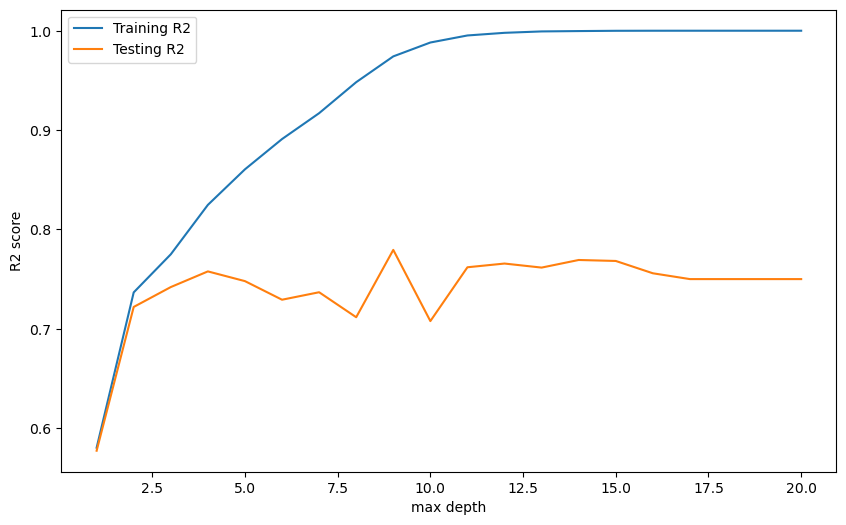

In [19]:
depths = range(1,21)
train_scores = []
test_scores = []

for d in depths:
    dlt_depth = DecisionTreeRegressor(max_depth=d,random_state=12)
    dlt_depth.fit(X_train_s,y_train)
    train_scores.append(dlt_depth.score(X_train_s,y_train))
    test_scores.append(dlt_depth.score(X_test_s,y_test))

plt.figure(figsize=(10,6))
plt.plot(depths,train_scores,label='Training R2')
plt.plot(depths,test_scores,label='Testing R2')
plt.xlabel('max depth')
plt.ylabel('R2 score')
plt.legend()
plt.show()

In [20]:
df.shape

(392, 8)

## Synthetic data: the same curve on made-up data

In [73]:
from sklearn.datasets import make_regression, make_classification

In [74]:
X,y = make_regression(100000,noise=0.1,random_state=12)

In [75]:
# - train test splot
# - decision regressor
# - RMSE R2score
# - plot training and testing r2

In [76]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=12)

In [77]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [78]:
dlt = DecisionTreeRegressor(max_depth=11,random_state=12)
dlt.fit(X_train_s,y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,11
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,12
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [79]:
y_pred = dlt.predict(X_test_s)

In [80]:
r2_score(y_test,y_pred)

0.8322960766627407

In [81]:
np.sqrt(mean_squared_error(y_test,y_pred))

np.float64(63.73291908655854)

Text(0.5, 1.0, 'Residual vs Prediction')

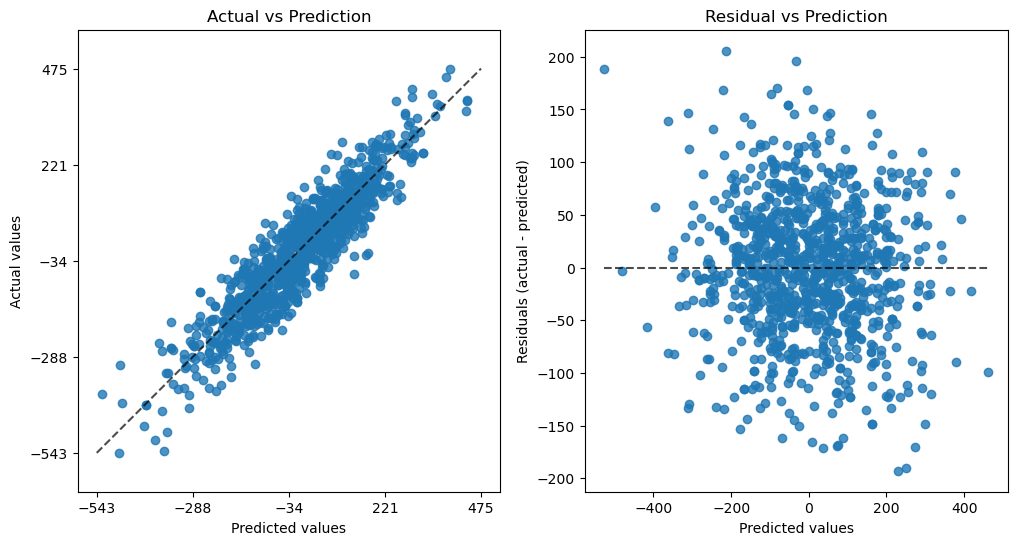

In [82]:
fig,axes = plt.subplots(1,2,figsize=(12,6))
PredictionErrorDisplay.from_predictions(y_test,y_pred,ax=axes[0],kind='actual_vs_predicted')
axes[0].set_title('Actual vs Prediction')
PredictionErrorDisplay.from_predictions(y_test,y_pred,ax=axes[1])
axes[1].set_title('Residual vs Prediction')

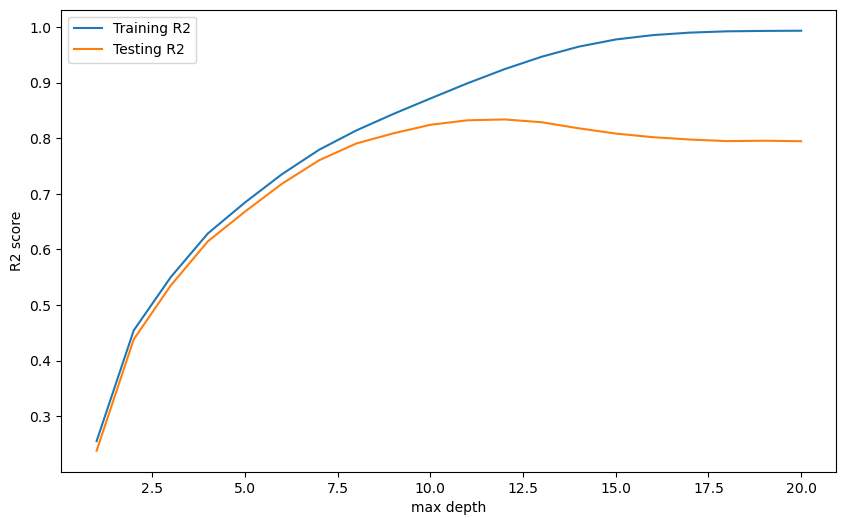

In [71]:
depths = range(1,21)
train_scores = []
test_scores = []

for d in depths:
    dlt_depth = DecisionTreeRegressor(max_depth=d,random_state=12)
    dlt_depth.fit(X_train,y_train)
    train_scores.append(dlt_depth.score(X_train_s,y_train))
    test_scores.append(dlt_depth.score(X_test_s,y_test))

plt.figure(figsize=(10,6))
plt.plot(depths,train_scores,label='Training R2')
plt.plot(depths,test_scores,label='Testing R2')
plt.xlabel('max depth')
plt.ylabel('R2 score')
plt.legend()
plt.show()

In [107]:
X,y = make_classification(n_samples=1000000,n_features=23,n_informative=15,n_redundant=8,random_state=12)

In [108]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=12)

In [109]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [110]:
clf = DecisionTreeClassifier(random_state=12)
clf.fit(X_train_s,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,12
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,12
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [111]:
y_pred = clf.predict(X_test_s)

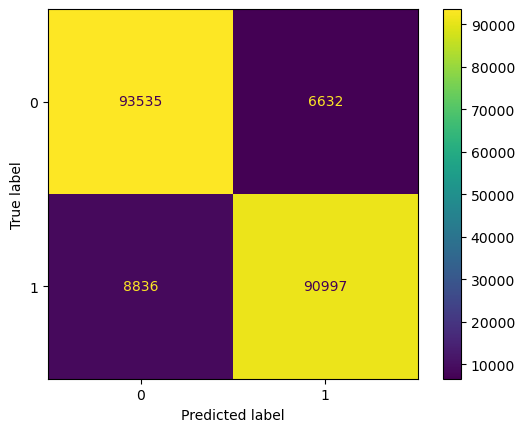

In [112]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)

In [113]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.91      0.93      0.92    100167
           1       0.93      0.91      0.92     99833

    accuracy                           0.92    200000
   macro avg       0.92      0.92      0.92    200000
weighted avg       0.92      0.92      0.92    200000



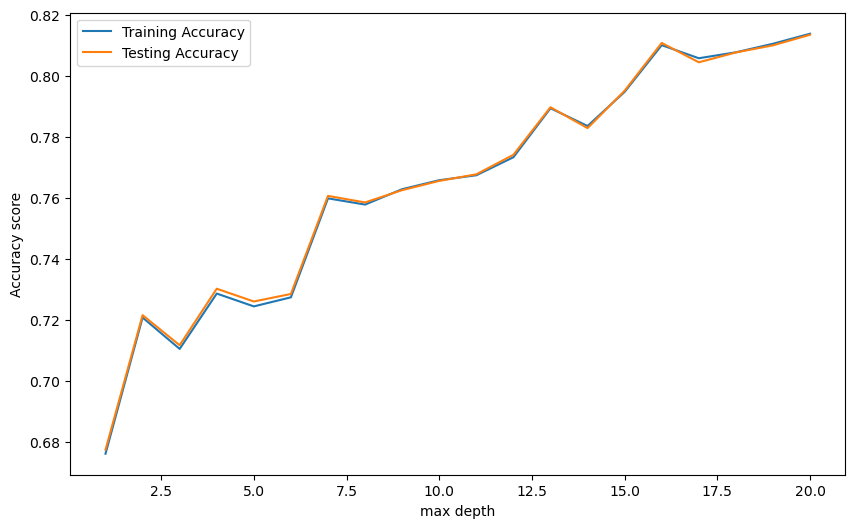

In [114]:
depths = range(1,21)
train_scores = []
test_scores = []

for d in depths:
    dlt_depth = DecisionTreeClassifier(max_depth=d,random_state=12)
    dlt_depth.fit(X_train,y_train)
    train_scores.append(dlt_depth.score(X_train_s,y_train))
    test_scores.append(dlt_depth.score(X_test_s,y_test))

plt.figure(figsize=(10,6))
plt.plot(depths,train_scores,label='Training Accuracy')
plt.plot(depths,test_scores,label='Testing Accuracy')
plt.xlabel('max depth')
plt.ylabel('Accuracy score')
plt.legend()
plt.show()